In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from google.colab import drive
from scipy.optimize import curve_fit
# Montar Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipython-input-2139440188.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-2139440188.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


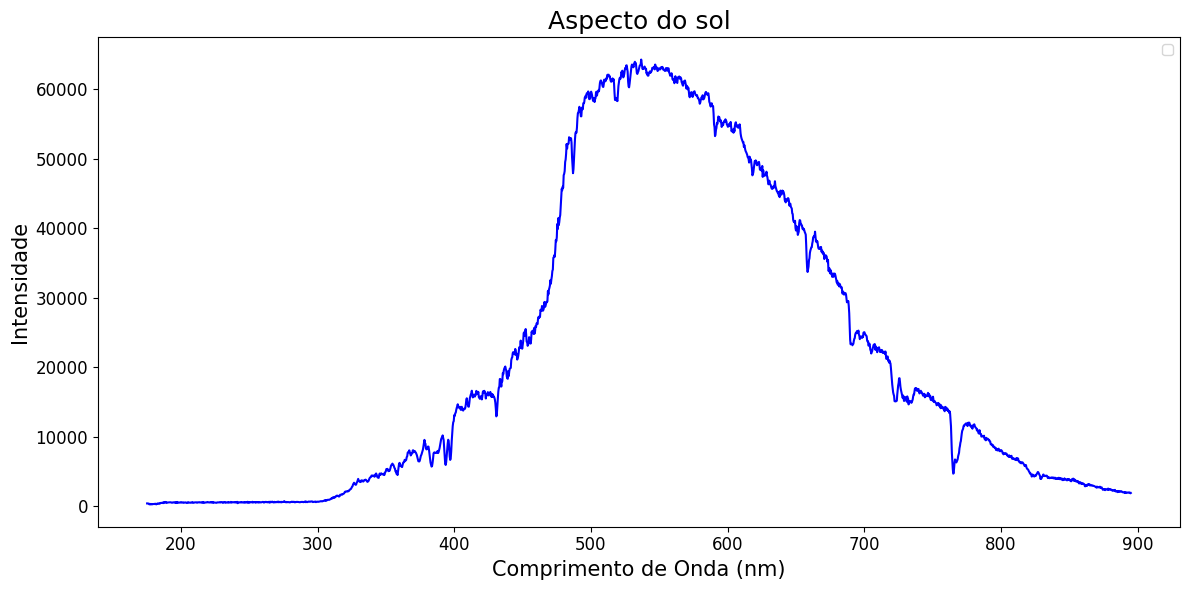

In [31]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/CORPOS NEGROS/ESPEC_SOL_DIA28_g1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')


# Estética do gráfico
plt.title("Aspecto do sol",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()


/tmp/ipython-input-2916705928.py:63: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-2916705928.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Os valores dos picos são: [536.77]


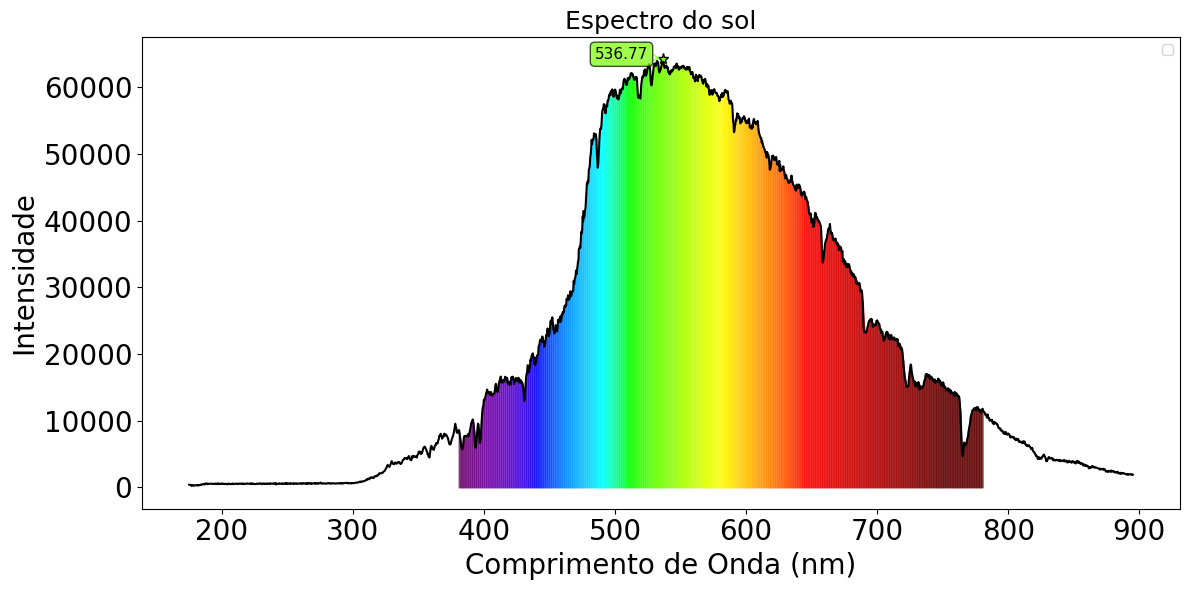

Pico em x = 536.77 ± 46.72 (FWHM = 228.88)


In [34]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

def wavelength_to_rgb(wavelength, gamma=0.8):
    ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
    This converts a given wavelength of light to an
    approximate RGB color value. The wavelength must be given
    in nanometers in the range from 380 nm through 750 nm
    (789 THz through 400 THz).

    Based on code by Dan Bruton
    http://www.physics.sfasu.edu/astro/color/spectra.html
    Additionally alpha value set to 0.5 outside range
    '''
    wavelength = float(wavelength)
    if wavelength >= 380 and wavelength <= 750:
        A = 1.
    else:
        A=0.5
    if wavelength < 380:
        wavelength = 380.
    if wavelength >750:
        wavelength = 750.
    if wavelength >= 380 and wavelength <= 440:
        attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
        R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
        G = 0.0
        B = (1.0 * attenuation) ** gamma
    elif wavelength >= 440 and wavelength <= 490:
        R = 0.0
        G = ((wavelength - 440) / (490 - 440)) ** gamma
        B = 1.0
    elif wavelength >= 490 and wavelength <= 510:
        R = 0.0
        G = 1.0
        B = (-(wavelength - 510) / (510 - 490)) ** gamma
    elif wavelength >= 510 and wavelength <= 580:
        R = ((wavelength - 510) / (580 - 510)) ** gamma
        G = 1.0
        B = 0.0
    elif wavelength >= 580 and wavelength <= 645:
        R = 1.0
        G = (-(wavelength - 645) / (645 - 580)) ** gamma
        B = 0.0
    elif wavelength >= 645 and wavelength <= 750:
        attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
        R = (1.0 * attenuation) ** gamma
        G = 0.0
        B = 0.0
    else:
        R = 0.0
        G = 0.0
        B = 0.0
    return (R,G,B,A)


# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/CORPOS NEGROS/ESPEC_SOL_DIA28_g1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=60000, distance=1000, prominence=1500)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='black')

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = wavelength_to_rgb(x[pico])
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=11)

#######Espectro sob a curva########
step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
for i in range(0, len(x) - 1, step):
    if 380 <= x[i] <= 780:
        lambda_medio = (x[i] + x[i+1]) / 2
        rgb = wavelength_to_rgb(lambda_medio)

        plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                         [y[i], y[min(i+step, len(x)-1)]],
                         color=rgb, alpha=0.6)


plt.title("Espectro do sol",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=20)
plt.ylabel("Intensidade",fontsize=20)
plt.legend()
plt.tick_params(labelsize=20)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-2388233911.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-2388233911.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


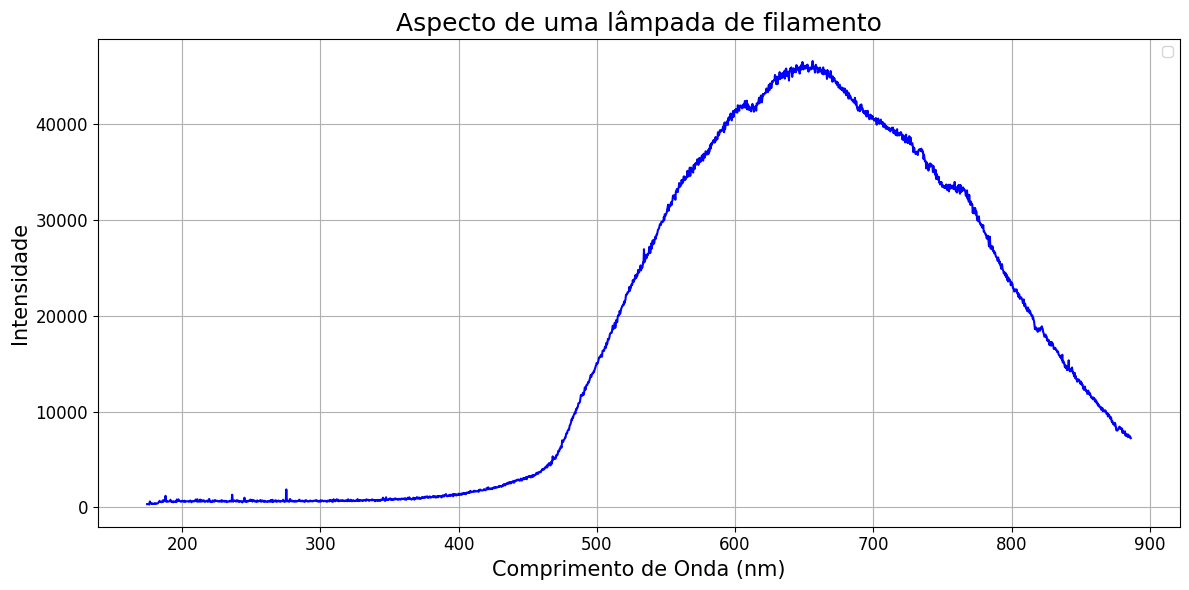

In [12]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/CORPOS NEGROS/Lampada_filamento.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')


# Estética do gráfico
plt.grid(True)
plt.title("Aspecto de uma lâmpada de filamento",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()


/tmp/ipython-input-20006655.py:63: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [656.09]


/tmp/ipython-input-20006655.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


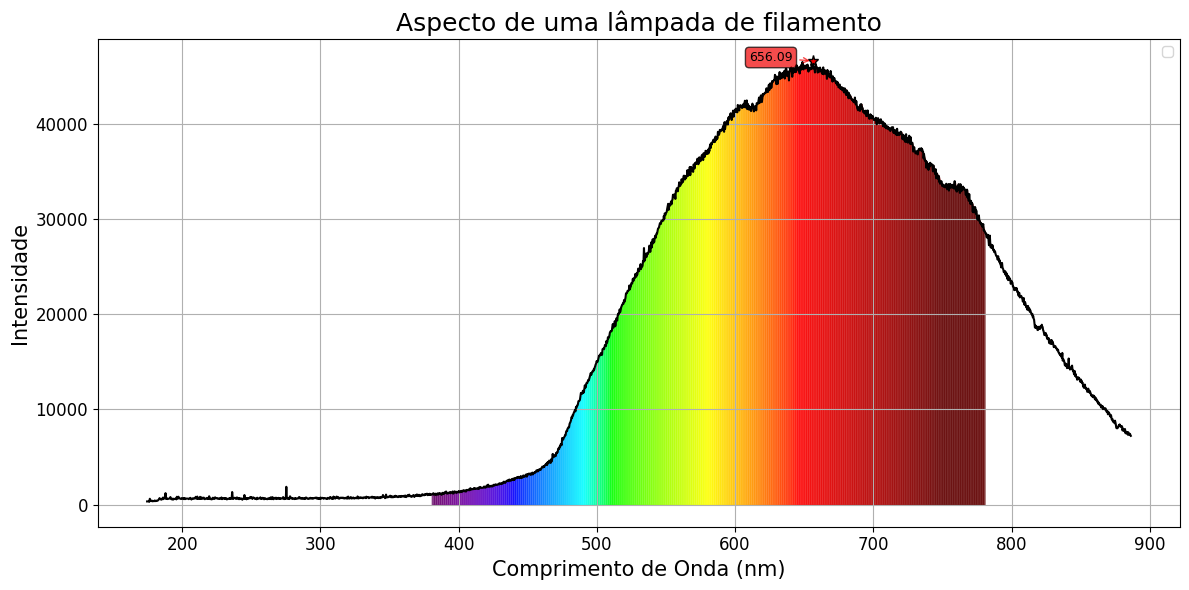

Pico em x = 656.09 ± 59.18 (FWHM = 289.91)


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

def wavelength_to_rgb(wavelength, gamma=0.8):
    ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
    This converts a given wavelength of light to an
    approximate RGB color value. The wavelength must be given
    in nanometers in the range from 380 nm through 750 nm
    (789 THz through 400 THz).

    Based on code by Dan Bruton
    http://www.physics.sfasu.edu/astro/color/spectra.html
    Additionally alpha value set to 0.5 outside range
    '''
    wavelength = float(wavelength)
    if wavelength >= 380 and wavelength <= 750:
        A = 1.
    else:
        A=0.5
    if wavelength < 380:
        wavelength = 380.
    if wavelength >750:
        wavelength = 750.
    if wavelength >= 380 and wavelength <= 440:
        attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
        R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
        G = 0.0
        B = (1.0 * attenuation) ** gamma
    elif wavelength >= 440 and wavelength <= 490:
        R = 0.0
        G = ((wavelength - 440) / (490 - 440)) ** gamma
        B = 1.0
    elif wavelength >= 490 and wavelength <= 510:
        R = 0.0
        G = 1.0
        B = (-(wavelength - 510) / (510 - 490)) ** gamma
    elif wavelength >= 510 and wavelength <= 580:
        R = ((wavelength - 510) / (580 - 510)) ** gamma
        G = 1.0
        B = 0.0
    elif wavelength >= 580 and wavelength <= 645:
        R = 1.0
        G = (-(wavelength - 645) / (645 - 580)) ** gamma
        B = 0.0
    elif wavelength >= 645 and wavelength <= 750:
        attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
        R = (1.0 * attenuation) ** gamma
        G = 0.0
        B = 0.0
    else:
        R = 0.0
        G = 0.0
        B = 0.0
    return (R,G,B,A)


# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/CORPOS NEGROS/Lampada_filamento.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=1000, distance=150, prominence=1500)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='black')

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = wavelength_to_rgb(x[pico])
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

#######Espectro sob a curva########
step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
for i in range(0, len(x) - 1, step):
    if 380 <= x[i] <= 780:
        lambda_medio = (x[i] + x[i+1]) / 2
        rgb = wavelength_to_rgb(lambda_medio)

        plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                         [y[i], y[min(i+step, len(x)-1)]],
                         color=rgb, alpha=0.6)

plt.title("Aspecto de uma lâmpada de filamento",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-4118012571.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-4118012571.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


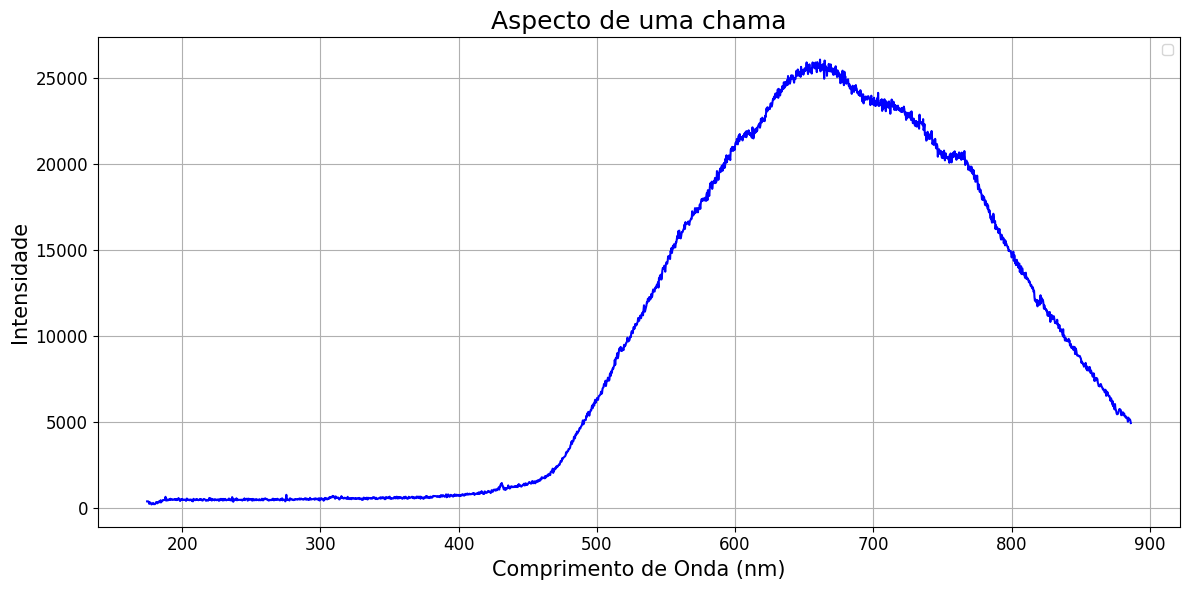

In [14]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/CORPOS NEGROS/isqueiro1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')


# Estética do gráfico
plt.grid(True)
plt.title("Aspecto de uma chama",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()


/tmp/ipython-input-2561012120.py:63: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-2561012120.py:117: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Os valores dos picos são: [661.43]


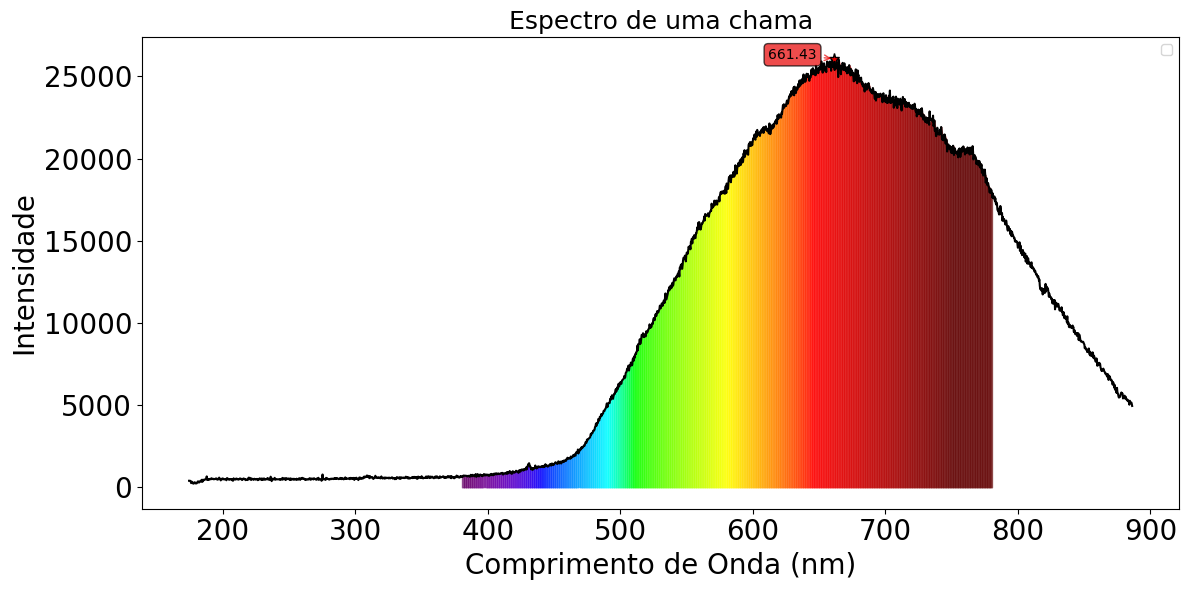

Pico em x = 661.43 ± 56.86 (FWHM = 278.57)


In [30]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

def wavelength_to_rgb(wavelength, gamma=0.8):
    ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
    This converts a given wavelength of light to an
    approximate RGB color value. The wavelength must be given
    in nanometers in the range from 380 nm through 750 nm
    (789 THz through 400 THz).

    Based on code by Dan Bruton
    http://www.physics.sfasu.edu/astro/color/spectra.html
    Additionally alpha value set to 0.5 outside range
    '''
    wavelength = float(wavelength)
    if wavelength >= 380 and wavelength <= 750:
        A = 1.
    else:
        A=0.5
    if wavelength < 380:
        wavelength = 380.
    if wavelength >750:
        wavelength = 750.
    if wavelength >= 380 and wavelength <= 440:
        attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
        R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
        G = 0.0
        B = (1.0 * attenuation) ** gamma
    elif wavelength >= 440 and wavelength <= 490:
        R = 0.0
        G = ((wavelength - 440) / (490 - 440)) ** gamma
        B = 1.0
    elif wavelength >= 490 and wavelength <= 510:
        R = 0.0
        G = 1.0
        B = (-(wavelength - 510) / (510 - 490)) ** gamma
    elif wavelength >= 510 and wavelength <= 580:
        R = ((wavelength - 510) / (580 - 510)) ** gamma
        G = 1.0
        B = 0.0
    elif wavelength >= 580 and wavelength <= 645:
        R = 1.0
        G = (-(wavelength - 645) / (645 - 580)) ** gamma
        B = 0.0
    elif wavelength >= 645 and wavelength <= 750:
        attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
        R = (1.0 * attenuation) ** gamma
        G = 0.0
        B = 0.0
    else:
        R = 0.0
        G = 0.0
        B = 0.0
    return (R,G,B,A)


# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/CORPOS NEGROS/isqueiro1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=1000, distance=150, prominence=1500)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='black')



# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = wavelength_to_rgb(x[pico])
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=10)

#######Espectro sob a curva########
step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
for i in range(0, len(x) - 1, step):
    if 380 <= x[i] <= 780:
        lambda_medio = (x[i] + x[i+1]) / 2
        rgb = wavelength_to_rgb(lambda_medio)

        plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                         [y[i], y[min(i+step, len(x)-1)]],
                         color=rgb, alpha=0.6)


plt.title("Espectro de uma chama",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=20)
plt.ylabel("Intensidade",fontsize=20)
plt.legend()
plt.tick_params(labelsize=20)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-212152267.py:63: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-212152267.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Os valores dos picos são: [658.17]


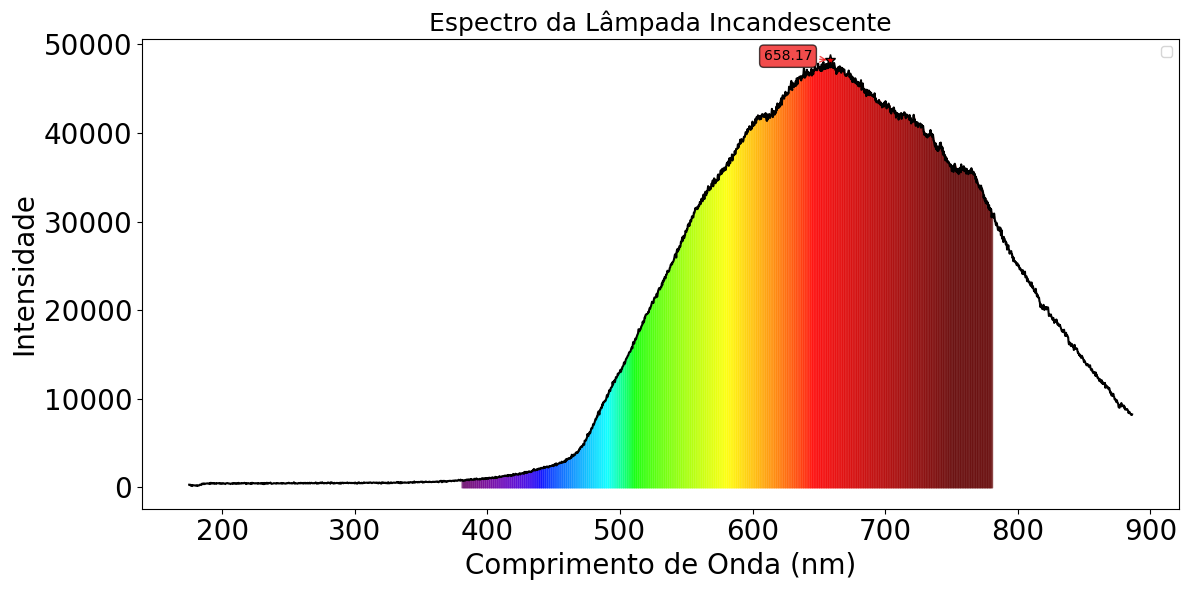

Pico em x = 658.17 ± 57.36 (FWHM = 281.01)


In [32]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

def wavelength_to_rgb(wavelength, gamma=0.8):
    ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
    This converts a given wavelength of light to an
    approximate RGB color value. The wavelength must be given
    in nanometers in the range from 380 nm through 750 nm
    (789 THz through 400 THz).

    Based on code by Dan Bruton
    http://www.physics.sfasu.edu/astro/color/spectra.html
    Additionally alpha value set to 0.5 outside range
    '''
    wavelength = float(wavelength)
    if wavelength >= 380 and wavelength <= 750:
        A = 1.
    else:
        A=0.5
    if wavelength < 380:
        wavelength = 380.
    if wavelength >750:
        wavelength = 750.
    if wavelength >= 380 and wavelength <= 440:
        attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
        R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
        G = 0.0
        B = (1.0 * attenuation) ** gamma
    elif wavelength >= 440 and wavelength <= 490:
        R = 0.0
        G = ((wavelength - 440) / (490 - 440)) ** gamma
        B = 1.0
    elif wavelength >= 490 and wavelength <= 510:
        R = 0.0
        G = 1.0
        B = (-(wavelength - 510) / (510 - 490)) ** gamma
    elif wavelength >= 510 and wavelength <= 580:
        R = ((wavelength - 510) / (580 - 510)) ** gamma
        G = 1.0
        B = 0.0
    elif wavelength >= 580 and wavelength <= 645:
        R = 1.0
        G = (-(wavelength - 645) / (645 - 580)) ** gamma
        B = 0.0
    elif wavelength >= 645 and wavelength <= 750:
        attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
        R = (1.0 * attenuation) ** gamma
        G = 0.0
        B = 0.0
    else:
        R = 0.0
        G = 0.0
        B = 0.0
    return (R,G,B,A)


# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./medicoes 3 dia/corpo negro dia 3/corponegro_lampada_semfiltro'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=40000, distance=1000, prominence=1500)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='black')

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = wavelength_to_rgb(x[pico])
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=10)

#######Espectro sob a curva########
step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
for i in range(0, len(x) - 1, step):
    if 380 <= x[i] <= 780:
        lambda_medio = (x[i] + x[i+1]) / 2
        rgb = wavelength_to_rgb(lambda_medio)

        plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                         [y[i], y[min(i+step, len(x)-1)]],
                         color=rgb, alpha=0.6)


plt.title("Espectro da Lâmpada Incandescente",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=20)
plt.ylabel("Intensidade",fontsize=20)
plt.legend()
plt.tick_params(labelsize=20)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-2109782017.py:63: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [722.5]


/tmp/ipython-input-2109782017.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


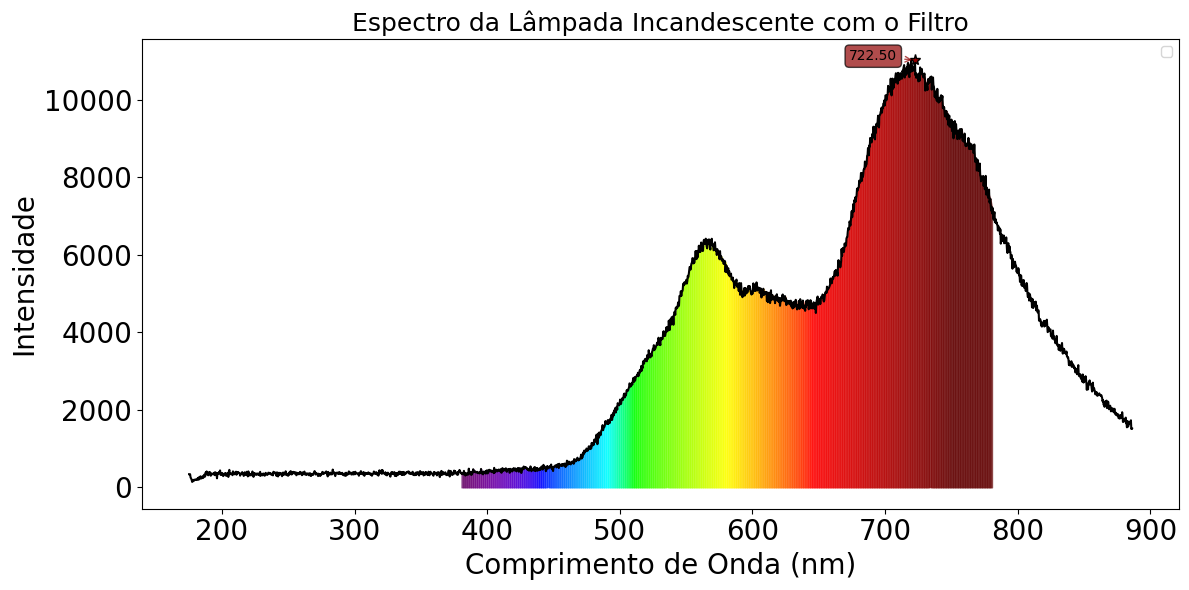

Pico em x = 722.50 ± 29.76 (FWHM = 145.82)


In [33]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

def wavelength_to_rgb(wavelength, gamma=0.8):
    ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
    This converts a given wavelength of light to an
    approximate RGB color value. The wavelength must be given
    in nanometers in the range from 380 nm through 750 nm
    (789 THz through 400 THz).

    Based on code by Dan Bruton
    http://www.physics.sfasu.edu/astro/color/spectra.html
    Additionally alpha value set to 0.5 outside range
    '''
    wavelength = float(wavelength)
    if wavelength >= 380 and wavelength <= 750:
        A = 1.
    else:
        A=0.5
    if wavelength < 380:
        wavelength = 380.
    if wavelength >750:
        wavelength = 750.
    if wavelength >= 380 and wavelength <= 440:
        attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
        R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
        G = 0.0
        B = (1.0 * attenuation) ** gamma
    elif wavelength >= 440 and wavelength <= 490:
        R = 0.0
        G = ((wavelength - 440) / (490 - 440)) ** gamma
        B = 1.0
    elif wavelength >= 490 and wavelength <= 510:
        R = 0.0
        G = 1.0
        B = (-(wavelength - 510) / (510 - 490)) ** gamma
    elif wavelength >= 510 and wavelength <= 580:
        R = ((wavelength - 510) / (580 - 510)) ** gamma
        G = 1.0
        B = 0.0
    elif wavelength >= 580 and wavelength <= 645:
        R = 1.0
        G = (-(wavelength - 645) / (645 - 580)) ** gamma
        B = 0.0
    elif wavelength >= 645 and wavelength <= 750:
        attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
        R = (1.0 * attenuation) ** gamma
        G = 0.0
        B = 0.0
    else:
        R = 0.0
        G = 0.0
        B = 0.0
    return (R,G,B,A)


# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./medicoes 3 dia/corpo negro dia 3/corponegro_lampada_comfiltro'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=10000, distance=1000, prominence=1500)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='black')

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = wavelength_to_rgb(x[pico])
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=10)

#######Espectro sob a curva########
step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
for i in range(0, len(x) - 1, step):
    if 380 <= x[i] <= 780:
        lambda_medio = (x[i] + x[i+1]) / 2
        rgb = wavelength_to_rgb(lambda_medio)

        plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                         [y[i], y[min(i+step, len(x)-1)]],
                         color=rgb, alpha=0.6)


plt.title("Espectro da Lâmpada Incandescente com o Filtro",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=20)
plt.ylabel("Intensidade",fontsize=20)
plt.legend()
plt.tick_params(labelsize=20)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


In [37]:
import numpy as np

# Lei de Wien: λ_max * T = b (onde b = 2.897771955e-3 m·K)
def lei_de_wien(lambda_nm):
    """
    Calcula a temperatura usando a Lei de Wien.

    Parâmetros:
    lambda_nm : float ou array
        Comprimento de onda em nanômetros

    Retorna:
    tuple : (T_kelvin, T_celsius)
    """
    b = 2.897771955e-3  # Constante de Wien em m·K
    lambda_m = lambda_nm * 1e-9  # Converte nm para metros

    T_kelvin = b / lambda_m
    T_celsius = T_kelvin - 273.15

    return T_kelvin, T_celsius

# Valores de comprimento de onda fornecidos
lambdas_nm = [536.77, 658.17, 661.43]

print("Cálculo de Temperatura pela Lei de Wien")
print("=" * 50)
print(f"{'λ (nm)':<10} {'T (K)':<12} {'T (°C)':<12}")
print("-" * 50)

for lambda_nm in lambdas_nm:
    T_k, T_c = lei_de_wien(lambda_nm)
    print(f"{lambda_nm:<10.2f} {T_k:<12.2f} {T_c:<12.2f}")

print("=" * 50)

Cálculo de Temperatura pela Lei de Wien
λ (nm)     T (K)        T (°C)      
--------------------------------------------------
536.77     5398.54      5125.39     
658.17     4402.77      4129.62     
661.43     4381.07      4107.92     


In [39]:
import numpy as np

lambdas = np.array([536.77, 658.17, 661.43]) * 1e-9
dl = 0.4e-9
b = 2.897771955e-3

T = b / lambdas
dT = (b / lambdas**2) * dl

for lam, t, dt in zip(lambdas*1e9, T, dT):
    print(f"λ = {lam:.2f} nm -> "
          f"T = {t:.2f} ± {dt:.2f} K, "
          f"T = {t-273.15:.2f} ± {dt:.2f} °C")


λ = 536.77 nm -> T = 5398.54 ± 4.02 K, T = 5125.39 ± 4.02 °C
λ = 658.17 nm -> T = 4402.77 ± 2.68 K, T = 4129.62 ± 2.68 °C
λ = 661.43 nm -> T = 4381.07 ± 2.65 K, T = 4107.92 ± 2.65 °C
